In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import binom
from scipy.stats import poisson

Load the dataset

In [2]:
#Trips, Nights and Average Length of Stay of Foreign Resident Overnight Visitors
#dataset downloaded from 
# ITM05 https://data.cso.ie/#

tourism=pd.read_csv('Length of Stay of Foreign Resident.csv')

head to see the first 5 raws

In [3]:
tourism.head()

,Statistic Label,Month,Main Accommodation Type,UNIT,VALUE
0,Number of Overnight Trips by Foreign Visitors,2023 January,Hotel/conference centre,Thousand,121.0
1,Number of Overnight Trips by Foreign Visitors,2023 January,Guest house/bed & breakfast,Thousand,8.5
2,Number of Overnight Trips by Foreign Visitors,2023 January,Friends/relatives/own property,Thousand,243.4
3,Number of Overnight Trips by Foreign Visitors,2023 January,Self catering/rented house,Thousand,13.8
4,Number of Overnight Trips by Foreign Visitors,2023 January,Other private tourism accommodation n.e.c.,Thousand,13.4


In [4]:
#to see how many columns and rows it has
tourism.shape

(1320, 5)

In [5]:
#to see if we have nulls and how many columns
tourism.info()

<class 'pandas.DataFrame'>
RangeIndex: 1320 entries, 0 to 1319
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Statistic Label          1320 non-null   str    
 1   Month                    1320 non-null   str    
 2   Main Accommodation Type  1320 non-null   str    
 3   UNIT                     1320 non-null   str    
 4   VALUE                    1320 non-null   float64
dtypes: float64(1), str(4)
memory usage: 166.4 KB


In [6]:
# stadistic properties mean, std, min
tourism.describe()

,VALUE
count,1320.000000
mean,328.579621
std,854.248511
min,1.000000
25%,8.175000
50%,34.000000
75%,204.700000
max,7337.700000


In [7]:
# I can see what types of data I have, mostly str
tourism.dtypes

Statistic Label                str
Month                          str
Main Accommodation Type        str
UNIT                           str
VALUE                      float64
dtype: object

In [8]:
# to see if there are columns missing values
tourism.isnull().sum()

Statistic Label            0
Month                      0
Main Accommodation Type    0
UNIT                       0
VALUE                      0
dtype: int64

**Exploratory Data Analysis (EDA)**

Before applying any statistical models, an Exploratory Data Analysis was conducted to understand the dataset's structure and quality.

**Data Quality Insights:**

1. Structure & Types: The dataset has 1,320 rows and 5 columns. We have 4 string columns (categorical) and 1 numeric column (VALUE), which is already a float.
2. Missing Values: isnull().sum() confirmed there are no missing values, so no imputation is required for the raw dataset.
3. Data Structure (Wide vs Long): The value_counts() method revealed that VALUE mixes 5 different metrics (trips, nights, percentages, etc.). Mixing these would yield invalid statistics, which justified filtering by Statistic Label for all subsequent analyses.
4. Distribution & Outliers: Using boxplots and the IQR method, we identified 14 outliers in the Number of Overnight Trips. The histogram of Average Length of Stay showed a strong right-skew, indicating non-normality.
* Conclusion: The EDA revealed that the raw data requires careful filtering (by metric) before analysis. For Machine Learning, the dataset will need to be pivoted (wide format) and the categorical variables (Accommodation Type, Month) will need encoding.

# Correlation

"For the correlation analysis and subsequent ML phases, the dataset was pivoted to a wide format to separate the metrics".

In [9]:
# Pivot dataset to wide format
ml_df = tourism.pivot_table(
    index=['Month', 'Main Accommodation Type'],
    columns='Statistic Label',
    values='VALUE'
).reset_index()

# Rename columns using a dictionary
ml_df = ml_df.rename(columns={
    'Average Length of Stay of Foreign Visitors': 'Avg_LOS',
    'Number of Nights by Foreign Visitors': 'Nights',
    'Number of Overnight Trips by Foreign Visitors': 'Trips',
    'Percentage of Nights by Foreign Visitors': 'Pct_Nights',
    'Percentage of Overnight Trips by Foreign Visitors': 'Pct_Trips',
    'Main Accommodation Type': 'Accommodation'
})

# Check the column names and the first row to verify the fix
print("Column names:", ml_df.columns.tolist())
print(ml_df.head(1))

Column names: ['Month', 'Accommodation', 'Avg_LOS', 'Nights', 'Trips', 'Pct_Nights', 'Pct_Trips']
Statistic Label       Month               Accommodation  Avg_LOS  Nights  \
0                2023 April  All types of accommodation      7.9  3667.5   

Statistic Label  Trips  Pct_Nights  Pct_Trips  
0                461.9       100.0      100.0  


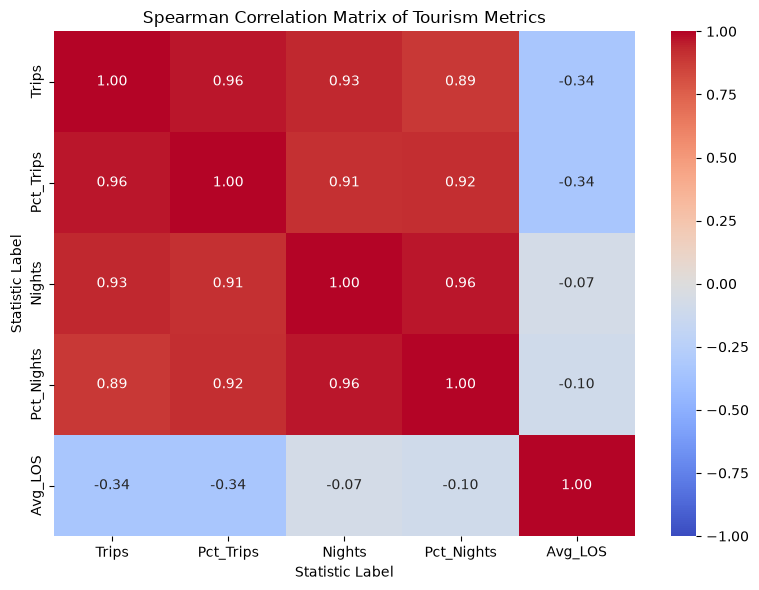

Spearman Correlation Matrix:


Statistic Label,Trips,Pct_Trips,Nights,Pct_Nights,Avg_LOS
Statistic Label,,,,,
Trips,1.00,0.96,0.93,0.89,-0.34
Pct_Trips,0.96,1.00,0.91,0.92,-0.34
Nights,0.93,0.91,1.00,0.96,-0.07
Pct_Nights,0.89,0.92,0.96,1.00,-0.10
Avg_LOS,-0.34,-0.34,-0.07,-0.10,1.00


In [10]:

# 1. Select only the numeric metric columns (exclude text and encoded columns)
corr_metrics = ml_df[['Trips', 'Pct_Trips', 'Nights', 'Pct_Nights', 'Avg_LOS']]

# 2. Calculate Spearman correlation (robust to non-normal data)
corr_matrix = corr_metrics.corr(method='spearman')

# 3. Plot the Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Spearman Correlation Matrix of Tourism Metrics')
plt.tight_layout()
plt.show()

# 4. Display the correlation matrix numerically
print("Spearman Correlation Matrix:")
display(corr_matrix.round(2))

**Correlation Analysis**

To understand the relationships between the five tourism metrics, a Spearman correlation matrix was generated on the pivoted dataset (`ml_df`). Spearman was chosen because the data is highly skewed and not normally distributed.

**Insights from the Heatmap:**
- **Strong Positive Correlation:** The *Number of Trips* and *Number of Nights* show a strong positive correlation (0.93). Months with more visitors logically generate more nights.
- **Weak/Moderate Correlation:** *Average Length of Stay* (Avg_LOS) shows a weak or negative correlation with both Trips (-0.34) and Nights (-0.07). This indicates that high volume (many trips) does not necessarily mean longer stays. Volume and duration are driven by different factors.
- **Data Leakage Prevention:** Although the correlation between Avg_LOS and the others is weak, *Avg_LOS* is mathematically derived from *Nights / Trips*. Therefore, including *Avg_LOS*, *Nights*, and *Trips* in the Machine Learning features would allow the model to reconstruct the answer, causing severe data leakage. These variables are excluded from the models.

**Source:** pandas Documentation. "pandas.DataFrame.corr".
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.corr.html
**How I found it:** I searched the official pandas documentation for correlation matrix calculations.
**Quality evaluation:** Official pandas documentation, maintained by the pandas development team. It is the primary source for correlation analysis.
**Verification:** I ran the code and confirmed that the output matrix matches the visual heatmap and correctly highlights the relationships between the metrics.

In [11]:
### Time Series Analysis (Seasonality)

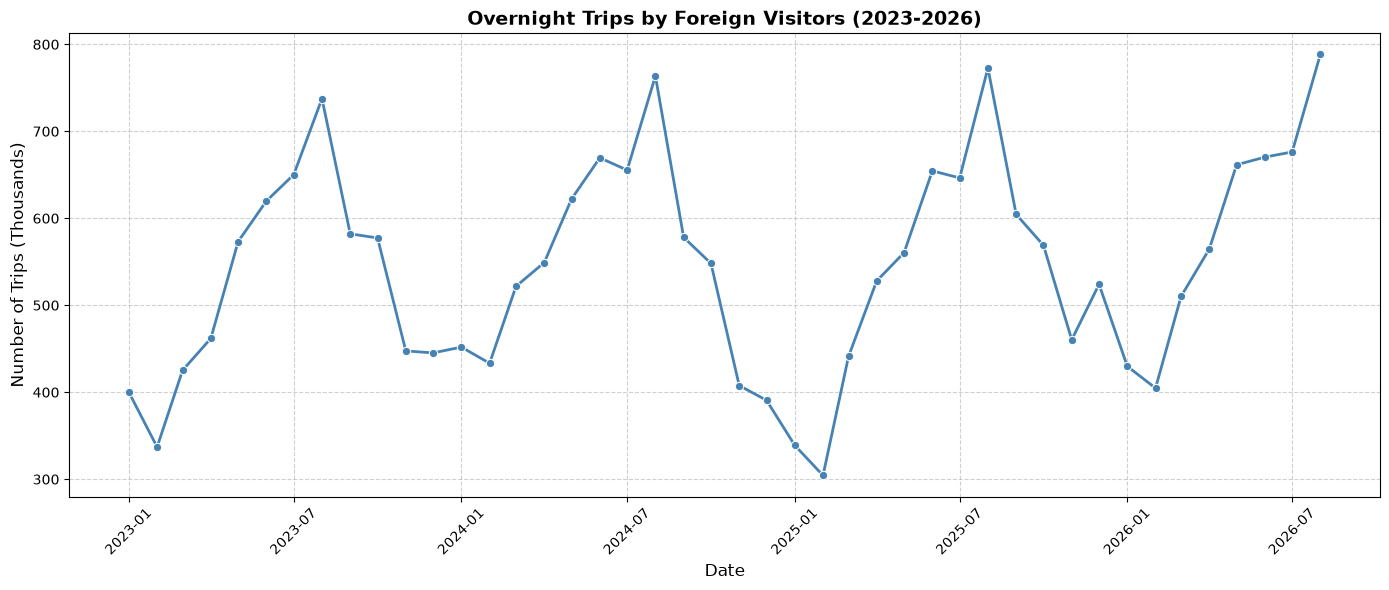

In [12]:


# Filter the dataset to isolate total overnight trips
total_trips = tourism[
    (tourism["Statistic Label"] == "Number of Overnight Trips by Foreign Visitors") & 
    (tourism["Main Accommodation Type"] == "All types of accommodation")
].copy()

# Convert the 'Month' column to datetime
total_trips['Date'] = pd.to_datetime(total_trips['Month'], format='%Y %B')

# Generate the time series plot
plt.figure(figsize=(14, 6))
sns.lineplot(data=total_trips, x='Date', y='VALUE', marker='o', color='steelblue', linewidth=2)

# Formatting
plt.title('Overnight Trips by Foreign Visitors (2023-2026)', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Number of Trips (Thousands)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

**Visual Insight: Seasonality (Time Series Plot)**

The line plot displays the evolution of total overnight trips over the analyzed period. This visualization was created to identify seasonal patterns. 

**Tufts Principles Justification:**
The graph adheres to Tufte Principles by displaying the data accurately without distortion (using raw trip counts on the y-axis) and making the data accessible (clear titles, rotated x-axis for readability).

**Insight Gained:** 
The graph clearly reveals the strong seasonal autocorrelation of Irish tourism. Trips peak dramatically during the summer months (July and August) and drop significantly in winter. This insight is critical, as it justifies why the discrete distributions (Binomial and Poisson) have limitations due to their independence assumptions, and it directly informed the creation of the target variable for the Machine Learning models.

**Source:** Pandas Documentation. "pandas.to_datetime".
https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html
**How I found it:** Searched the official pandas reference for converting string dates to datetime objects for plotting.
**Quality evaluation:** Primary source for pandas functions.
**Verification:** The code correctly converted the "Month" column and the resulting plot displayed a chronological timeline.

# Measure of central tendency

In [13]:
# To show the first 5 raws and all columns
tourism.head()

,Statistic Label,Month,Main Accommodation Type,UNIT,VALUE
0,Number of Overnight Trips by Foreign Visitors,2023 January,Hotel/conference centre,Thousand,121.0
1,Number of Overnight Trips by Foreign Visitors,2023 January,Guest house/bed & breakfast,Thousand,8.5
2,Number of Overnight Trips by Foreign Visitors,2023 January,Friends/relatives/own property,Thousand,243.4
3,Number of Overnight Trips by Foreign Visitors,2023 January,Self catering/rented house,Thousand,13.8
4,Number of Overnight Trips by Foreign Visitors,2023 January,Other private tourism accommodation n.e.c.,Thousand,13.4
